# HW2 : Uniform Convergence and the Limits of Learning

**BENZOHRA Elhachemi – M2 IMDS**


J'utilise seulement `numpy` pour les calculs et `matplotlib` pour les graphiques.

**Mes choix de paramètres**

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| $\varepsilon$ | 0.05 | écart toléré entre $L_S$ et $L_D$, assez petit pour qu'il faille plusieurs centaines d'exemples |
| $\delta$ | 0.05 | confiance de 95 % |
| $m$ (partie I) | 10 à 2000 | de très peu de données (beaucoup de fluctuations) à beaucoup (fluctuations faibles) |
| vraies erreurs $p_j$ | entre 0.05 et 0.5 | valeurs réalistes pour un classifieur ; 0.5 est le cas où $L_S$ varie le plus |
| $\lvert\mathcal{H}\rvert$ | 5, 10, 50, 100, 500 | tailles proposées dans le sujet, sur deux ordres de grandeur |
| répétitions | 10 000 (partie I), 4 000 (tailles de classe), 2 000 (parties II et III) | assez pour mesurer des probabilités de l'ordre de 0.001 à 0.01 ; un peu moins quand $\lvert\mathcal{H}\rvert = 500$ pour garder un temps de calcul court |
| $N$ | 20, 100, 500 puis 100 | plusieurs tailles de domaine pour la question 6, puis $N = 100$ pour comparer facilement |

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

# paramètres de la partie I
eps = 0.05                           # écart toléré entre L_S et L_D
delta = 0.05                         # probabilité d'échec tolérée
m_list = [10, 20, 50, 100, 200, 500, 1000, 2000]
n_rep = 10000                        # nombre de répétitions Monte-Carlo

## Partie I – Simuler la uniform convergence

Chaque hypothèse $h_j$ a une erreur vraie fixée $L_D(h_j) = p_j$. Sur un training set de taille $m$, son nombre d'erreurs suit $E_j \sim \text{Binomial}(m, p_j)$ et $L_S(h_j) = E_j / m$. On peut donc simuler $L_S$ directement, sans générer de données.

### 1. L'erreur empirique est une variable aléatoire

Je prends une hypothèse avec $p = 0.3$ et je simule 10 000 training sets pour chaque taille $m$. Je compare l'écart-type observé avec celui de la loi binomiale, $\sqrt{p(1-p)/m}$.

In [ ]:
p = 0.3                              # vraie erreur de l'hypothèse étudiée

print("   m   moyenne de L_S   écart-type de L_S   sqrt(p(1-p)/m)")
L_S = {}
for m in m_list:
    E = rng.binomial(m, p, n_rep)    # nombre d'erreurs sur n_rep training sets
    L_S[m] = E / m
    print(f"{m:5d}   {L_S[m].mean():14.4f}   {L_S[m].std():17.4f}   {np.sqrt(p*(1-p)/m):14.4f}")

   m   moyenne de L_S   écart-type de L_S   sqrt(p(1-p)/m)
   10           0.3029              0.1448           0.1449
   20           0.2991              0.1016           0.1025
   50           0.2991              0.0652           0.0648
  100           0.2990              0.0457           0.0458
  200           0.3004              0.0323           0.0324
  500           0.3000              0.0205           0.0205
 1000           0.2998              0.0145           0.0145
 2000           0.3002              0.0101           0.0102


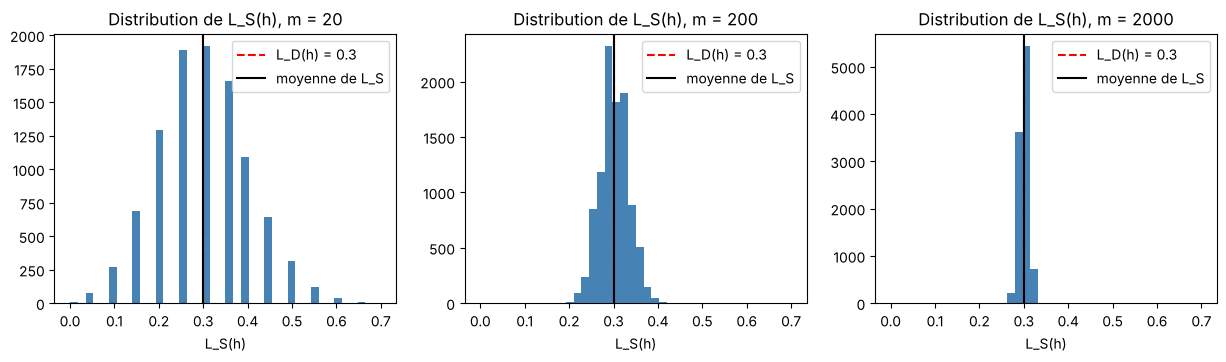

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for ax, m in zip(axes, [20, 200, 2000]):
    ax.hist(L_S[m], bins=40, range=(0, 0.7), color="steelblue")
    ax.axvline(p, color="red", linestyle="--", label="L_D(h) = 0.3")
    ax.axvline(L_S[m].mean(), color="black", label="moyenne de L_S")
    ax.set_title("Distribution de L_S(h), m = " + str(m))
    ax.set_xlabel("L_S(h)")
    ax.legend()
plt.show()

In [ ]:
print("    p    moyenne de L_S (m = 100)")
for pj in [0.05, 0.1, 0.2, 0.3, 0.5]:
    print(f"{pj:5.2f}   {np.mean(rng.binomial(100, pj, n_rep) / 100):10.4f}")

    p    moyenne de L_S (m = 100)
 0.05       0.0499
 0.10       0.1001
 0.20       0.1995
 0.30       0.2993
 0.50       0.4995


**Commentaire.**

- La moyenne de $L_S(h)$ vaut 0.30 pour toutes les tailles, et c'est vrai aussi pour les autres valeurs de $p$ (dernier tableau). En moyenne, l'erreur empirique donne donc la bonne valeur : c'est normal, car $E[E_j/m] = p_j$.
- Ce qui change avec $m$, c'est la dispersion : l'écart-type passe de 0.145 pour $m = 10$ à 0.010 pour $m = 2000$, exactement comme $\sqrt{p(1-p)/m}$. Quand $m$ est multiplié par 100, l'écart-type est divisé par 10.
- Sur les histogrammes, avec $m = 20$, $L_S$ peut tomber n'importe où entre 0.1 et 0.55 ; avec $m = 2000$, il reste presque toujours entre 0.28 et 0.32.

Avec peu de données, une hypothèse peut donc avoir l'air bien meilleure ou bien pire qu'elle ne l'est vraiment.

### 2. Écart entre erreur empirique et erreur vraie

Pour chaque training set simulé, je calcule $|L_S(h) - L_D(h)|$ et je compte la proportion de fois où cet écart dépasse $\varepsilon = 0.05$. Je compare avec la borne de Hoeffding $2e^{-2m\varepsilon^2}$ (coupée à 1, puisqu'une probabilité ne dépasse pas 1).

   m   P(|L_S - L_D| > eps)   borne de Hoeffding
   10                 0.7373               1.0000
   20                 0.4699               1.0000
   50                 0.4279               1.0000
  100                 0.2319               1.0000
  200                 0.1029               0.7358
  500                 0.0123               0.1642
 1000                 0.0005               0.0135
 2000                 0.0000               0.0001


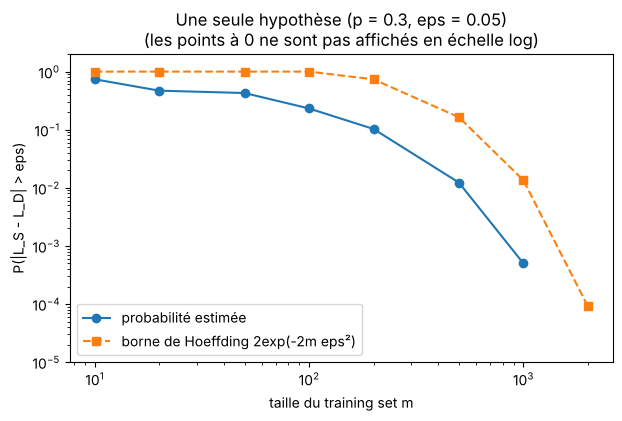

In [ ]:
print("   m   P(|L_S - L_D| > eps)   borne de Hoeffding")
proba_1h = []
hoeff = []
for m in m_list:
    L = rng.binomial(m, p, n_rep) / m
    proba_1h.append(np.mean(np.abs(L - p) > eps))
    hoeff.append(min(1, 2 * np.exp(-2 * m * eps**2)))
    print(f"{m:5d}   {proba_1h[-1]:20.4f}   {hoeff[-1]:18.4f}")

plt.figure(figsize=(7, 4))
plt.plot(m_list, np.where(np.array(proba_1h) > 0, proba_1h, np.nan), "o-", label="probabilité estimée")
plt.plot(m_list, hoeff, "s--", label="borne de Hoeffding 2exp(-2m eps²)")
plt.xscale("log")
plt.yscale("log")
plt.ylim(1e-5, 2)
plt.xlabel("taille du training set m")
plt.ylabel("P(|L_S - L_D| > eps)")
plt.title("Une seule hypothèse (p = 0.3, eps = 0.05)\n(les points à 0 ne sont pas affichés en échelle log)")
plt.legend()
plt.show()

**Commentaire.**

- La probabilité d'un écart plus grand que $\varepsilon$ diminue quand $m$ augmente : 0.74 pour $m = 10$, 0.23 pour $m = 100$, 0.012 pour $m = 500$ et plus aucun cas sur 10 000 pour $m = 2000$.
- La courbe n'est pas parfaitement régulière pour les petits $m$ (0.47 pour $m = 20$, 0.43 pour $m = 50$) : avec peu d'exemples, $L_S$ ne peut prendre que les valeurs $k/m$, ce qui crée des sauts.
- La borne de Hoeffding est toujours au-dessus de la probabilité observée. Elle vaut 1 jusqu'à $m = 100$ (elle ne dit donc rien), puis 0.16 pour $m = 500$ alors que la vraie valeur est 0.012, et 0.0135 pour $m = 1000$ contre 0.0005.

La borne est donc **conservative**, pas exacte. C'est normal : elle doit être vraie pour n'importe quelle variable bornée dans $[0, 1]$, donc pour le pire cas. Ici la variance $p(1-p) = 0.21$ est plus petite que la variance maximale $1/4$, et la borne ne tient pas compte de cette information. En revanche, elle a la bonne forme : elle décroît exponentiellement en $m$, comme la probabilité observée.

### 3. D'une hypothèse à toute la classe

Je prends maintenant une classe de 10 hypothèses avec des erreurs vraies réparties entre 0.05 et 0.5. Pour chaque training set simulé, je calcule les 10 erreurs empiriques, puis le plus grand écart

$$\Delta_S = \max_{h \in \mathcal{H}} |L_S(h) - L_D(h)|.$$

$\Delta_S \le \varepsilon$ veut dire exactement que $S$ est $\varepsilon$-representative. Je compare $\Pr[\Delta_S > \varepsilon]$ avec la borne $2|\mathcal{H}|e^{-2m\varepsilon^2}$.

*Remarque :* dans cette simulation simplifiée, les nombres d'erreurs des différentes hypothèses sont tirés indépendamment. Dans un vrai problème ils seraient corrélés, car toutes les hypothèses sont évaluées sur le même training set. La union bound, elle, n'a pas besoin de l'indépendance.

In [ ]:
# classe de 10 hypothèses avec des vraies erreurs entre 0.05 et 0.5
p_H = np.linspace(0.05, 0.5, 10)
K = len(p_H)
print("vraies erreurs :", np.round(p_H, 2))

def proba_uc(p_H, m, n_rep):
    # simule n_rep training sets et renvoie la proportion où max_h |L_S - L_D| > eps
    L = rng.binomial(m, p_H, size=(n_rep, len(p_H))) / m   # une ligne = un training set
    delta_S = np.max(np.abs(L - p_H), axis=1)
    return np.mean(delta_S > eps)

print()
print("   m   P(Delta_S > eps)   borne 2|H|exp(-2m eps²)")
proba_H = []
for m in m_list:
    proba_H.append(proba_uc(p_H, m, n_rep))
    borne = 2 * K * np.exp(-2 * m * eps**2)
    print(f"{m:5d}   {proba_H[-1]:16.4f}   {borne:22.4f}")

vraies erreurs : [0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5 ]

   m   P(Delta_S > eps)   borne 2|H|exp(-2m eps²)
   10             0.9999                  19.0246
   20             0.9994                  18.0967
   50             0.9891                  15.5760
  100             0.9065                  12.1306
  200             0.6216                   7.3576
  500             0.1186                   1.6417
 1000             0.0073                   0.1348
 2000             0.0000                   0.0009


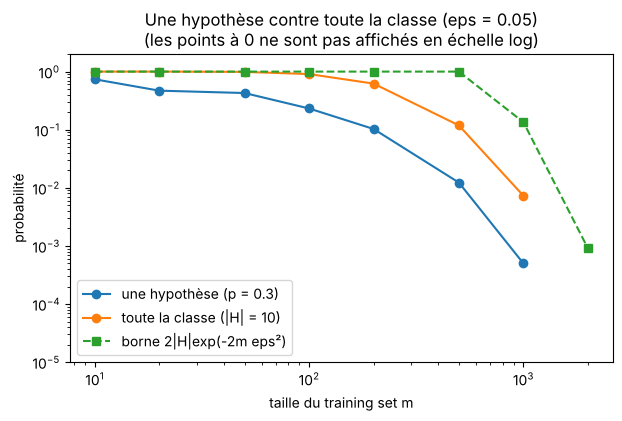

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(m_list, np.where(np.array(proba_1h) > 0, proba_1h, np.nan), "o-", label="une hypothèse (p = 0.3)")
plt.plot(m_list, np.where(np.array(proba_H) > 0, proba_H, np.nan), "o-", label="toute la classe (|H| = 10)")
plt.plot(m_list, [min(1, 2 * K * np.exp(-2 * m * eps**2)) for m in m_list], "s--", label="borne 2|H|exp(-2m eps²)")
plt.xscale("log")
plt.yscale("log")
plt.ylim(1e-5, 2)
plt.xlabel("taille du training set m")
plt.ylabel("probabilité")
plt.title("Une hypothèse contre toute la classe (eps = 0.05)\n(les points à 0 ne sont pas affichés en échelle log)")
plt.legend()
plt.show()

**Commentaire.**

- Il est beaucoup plus difficile de contrôler toute la classe qu'une seule hypothèse. Pour $m = 200$, la probabilité d'échec vaut 0.10 pour une hypothèse mais 0.62 pour la classe ; pour $m = 500$, 0.012 contre 0.12.
- C'est logique : il suffit qu'**une seule** des 10 hypothèses ait un écart trop grand pour que $\Delta_S > \varepsilon$. Plus il y a d'hypothèses, plus il y a de chances qu'une d'entre elles tombe loin de sa vraie erreur.
- Ce contrôle simultané est nécessaire parce que ERM choisit son hypothèse en regardant $S$ : il risque justement de choisir celle dont l'erreur empirique est trop optimiste.
- La borne $2|\mathcal{H}|e^{-2m\varepsilon^2}$ dépasse 1 jusqu'à $m = 500$ et vaut 0.13 pour $m = 1000$, alors que la probabilité observée est 0.007. Elle est encore plus pessimiste que pour une seule hypothèse, parce que la union bound additionne les probabilités comme si les mauvais événements ne se recouvraient jamais.

### 4. Effet de la taille de la classe

Je refais l'expérience avec $|\mathcal{H}| = 5, 10, 50, 100, 500$. Pour chaque classe, les erreurs vraies sont tirées une fois pour toutes, uniformément entre 0.05 et 0.5.

|H|   m=10      m=20      m=50      m=100     m=200     m=500     m=1000    m=2000 
  5     0.997     0.980     0.866     0.634     0.308     0.036     0.004     0.000
 10     1.000     1.000     0.996     0.944     0.709     0.162     0.011     0.000
 50     1.000     1.000     1.000     1.000     0.993     0.431     0.032     0.000
100     1.000     1.000     1.000     1.000     1.000     0.754     0.066     0.000
500     1.000     1.000     1.000     1.000     1.000     0.998     0.259     0.001


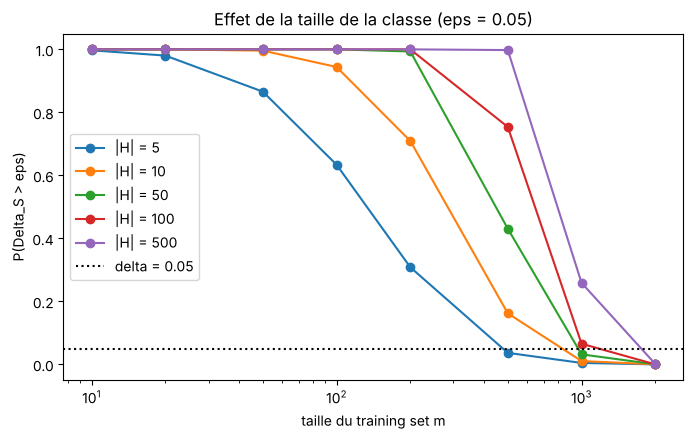

In [ ]:
tailles_H = [5, 10, 50, 100, 500]
gen = np.random.default_rng(0)
classes = {k: gen.uniform(0.05, 0.5, k) for k in tailles_H}   # vraies erreurs tirées une fois pour toutes

res_taille = {}
for k in tailles_H:
    res_taille[k] = [proba_uc(classes[k], m, 4000) for m in m_list]

print("|H|   " + "   ".join(f"m={m:<5d}" for m in m_list))
for k in tailles_H:
    print(f"{k:3d}   " + "   ".join(f"{v:7.3f}" for v in res_taille[k]))

plt.figure(figsize=(8, 4.5))
for k in tailles_H:
    plt.plot(m_list, res_taille[k], "o-", label="|H| = " + str(k))
plt.axhline(delta, color="black", linestyle=":", label="delta = 0.05")
plt.xscale("log")
plt.xlabel("taille du training set m")
plt.ylabel("P(Delta_S > eps)")
plt.title("Effet de la taille de la classe (eps = 0.05)")
plt.legend()
plt.show()

**Commentaire.**

- **Plus la classe est grande, plus il faut de données.** Pour $m = 500$, la probabilité d'échec vaut 0.04 avec 5 hypothèses, 0.43 avec 50 et 0.998 avec 500. Les courbes se décalent vers la droite quand $|\mathcal{H}|$ augmente.
- **Mais l'effet est faible.** Entre 5 et 500 hypothèses, la classe est 100 fois plus grande, alors que la taille nécessaire pour passer sous $\delta$ passe seulement d'environ 500 à environ 1350 (question 5).
- C'est ce que dit la borne théorique, qui dépend de $\log|\mathcal{H}|$ et pas de $|\mathcal{H}|$ : multiplier $|\mathcal{H}|$ par 100 ajoute seulement $\log(100)/(2\varepsilon^2) \approx 4.6/0.005 \approx 920$ exemples à la borne, au lieu de la multiplier par 100.

### 5. Sample complexity expérimentale

Pour $\varepsilon = 0.05$ et $\delta = 0.05$, je cherche, pour chaque taille de classe, le plus petit $m$ testé (de 50 en 50) tel que $\Pr[\Delta_S > \varepsilon] \le \delta$. Je le compare avec la taille suffisante donnée par la théorie :

$$m \ge \frac{\log(2|\mathcal{H}|/\delta)}{2\varepsilon^2}.$$

In [ ]:
grille_m = np.arange(50, 3001, 50)   # on teste m de 50 en 50

print("|H|   m expérimental   m théorique   rapport")
m_exp_list = []
m_th_list = []
for k in tailles_H:
    m_exp = None
    for m in grille_m:
        if proba_uc(classes[k], m, 4000) <= delta:
            m_exp = m
            break
    m_th = int(np.ceil(np.log(2 * k / delta) / (2 * eps**2)))
    m_exp_list.append(m_exp)
    m_th_list.append(m_th)
    print(f"{k:3d}   {m_exp:14d}   {m_th:11d}   {m_th / m_exp:7.2f}")

|H|   m expérimental   m théorique   rapport
  5              500          1060      2.12
 10              750          1199      1.60


 50              900          1521      1.69


100             1100          1659      1.51


500             1350          1981      1.47


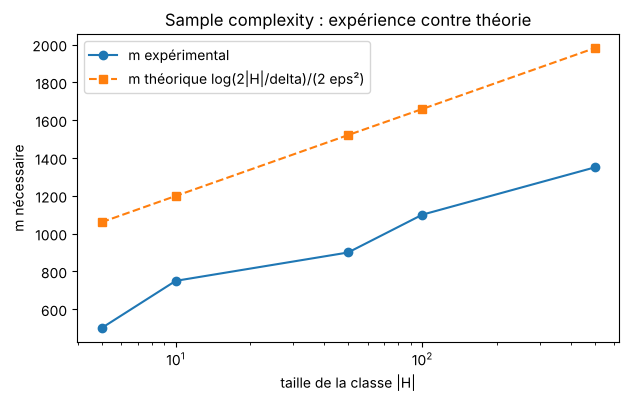

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(tailles_H, m_exp_list, "o-", label="m expérimental")
plt.plot(tailles_H, m_th_list, "s--", label="m théorique log(2|H|/delta)/(2 eps²)")
plt.xscale("log")
plt.xlabel("taille de la classe |H|")
plt.ylabel("m nécessaire")
plt.title("Sample complexity : expérience contre théorie")
plt.legend()
plt.show()

**Commentaire.**

| $\lvert\mathcal{H}\rvert$ | 5 | 10 | 50 | 100 | 500 |
|---|---|---|---|---|---|
| $m$ expérimental | 500 | 750 | 900 | 1100 | 1350 |
| $m$ théorique | 1060 | 1199 | 1521 | 1659 | 1981 |

- Dans tous les cas, la théorie demande entre 1.5 et 2 fois plus d'exemples que ce qui suffit en pratique.
- Les deux augmentent avec $|\mathcal{H}|$ et de façon lente (logarithmique), donc la théorie prévoit bien le bon comportement.

La borne doit être vue comme une **garantie suffisante**, pas comme la taille minimale exacte, pour trois raisons :
1. Hoeffding est écrit pour le pire cas (variance $1/4$), alors que nos hypothèses ont des erreurs entre 0.05 et 0.5, donc une variance souvent plus petite ;
2. la union bound additionne les probabilités d'échec de toutes les hypothèses, ce qui surestime la probabilité qu'au moins une échoue ;
3. la borne doit être valable pour **toutes** les distributions, alors que l'expérience n'en teste qu'une.

(Les valeurs expérimentales sont précises à 50 près, à cause de la grille testée.)

## Partie II – Simuler le No-Free-Lunch

Le domaine est $\mathcal{X} = \{1, \dots, N\}$ avec la loi uniforme. À chaque répétition, je tire une **nouvelle** fonction cible : chaque label $f(x)$ vaut 0 ou 1 avec probabilité 1/2, indépendamment. Chaque répétition est donc une nouvelle tâche d'apprentissage.

Le learner est très simple : si $x$ apparaît dans le training set, il prédit le label observé ; sinon il prédit 0 (je change cette règle à la question 8).

### 6. Points vus et points jamais vus

In [ ]:
def experience_nfl(N, m, n_rep, regle="0"):
    # renvoie la fraction moyenne de points non vus et le risque moyen du learner
    non_vus = np.zeros(n_rep)
    risque = np.zeros(n_rep)
    for r in range(n_rep):
        f = rng.integers(0, 2, N)            # nouvelle fonction cible aléatoire
        x = rng.integers(0, N, m)            # training set : m tirages uniformes dans X
        vu = np.zeros(N, dtype=bool)
        vu[x] = True
        if regle == "0":
            autre = np.zeros(N, dtype=int)
        elif regle == "1":
            autre = np.ones(N, dtype=int)
        else:
            autre = rng.integers(0, 2, N)    # label au hasard
        pred = np.where(vu, f, autre)        # label observé si vu, règle sinon
        non_vus[r] = 1 - vu.mean()
        risque[r] = np.mean(pred != f)
    return non_vus.mean(), risque.mean()

print("   N      m   non vus (simulation)   (1 - 1/N)^m")
for N in [20, 100, 500]:
    for m in [N // 2, N, 2 * N, 3 * N]:
        nv, _ = experience_nfl(N, m, 2000)
        print(f"{N:4d}   {m:4d}   {nv:20.4f}   {(1 - 1/N)**m:11.4f}")

   N      m   non vus (simulation)   (1 - 1/N)^m
  20     10                 0.5978        0.5987
  20     20                 0.3574        0.3585
  20     40                 0.1275        0.1285


  20     60                 0.0455        0.0461
 100     50                 0.6043        0.6050
 100    100                 0.3657        0.3660


 100    200                 0.1333        0.1340
 100    300                 0.0487        0.0490


 500    250                 0.6063        0.6062
 500    500                 0.3671        0.3675
 500   1000                 0.1352        0.1351


 500   1500                 0.0498        0.0496


**Commentaire.** La fraction moyenne de points jamais vus correspond à la formule $(1 - 1/N)^m$ à 0.001 près, pour toutes les valeurs de $N$ et $m$.

**Pourquoi cette formule.** À chaque tirage, un point fixé $x$ a une probabilité $1 - 1/N$ de ne pas être tiré. Les $m$ tirages sont indépendants, donc $\Pr[x \text{ non vu}] = (1 - 1/N)^m$.

**Pourquoi c'est aussi la fraction moyenne de points non vus.** La fraction de points non vus est $\frac{1}{N}\sum_{x} \mathbb{1}[x \text{ non vu}]$. Par linéarité de l'espérance, sa moyenne vaut $\frac{1}{N}\sum_x \Pr[x \text{ non vu}]$, et tous les points ont la même probabilité, donc on obtient $(1 - 1/N)^m$.

À noter : même avec autant de tirages que de points ($m = N$), environ 37 % du domaine reste jamais vu ($\approx e^{-1}$), à cause des répétitions.

### 7. Erreur sur les points jamais vus

**Calcul théorique.** Sur un point vu, le learner prédit le label observé, donc il a toujours raison (les labels ne sont pas bruités). Sur un point jamais vu, il prédit 0, alors que $f(x)$ vaut 0 ou 1 avec probabilité 1/2 et ne dépend pas de $S$ : il se trompe avec probabilité 1/2. Donc

$$E[L_D(A(S))] = \frac{1}{N}\sum_{x}\Pr[x \text{ non vu}] \times \frac{1}{2} = \frac{1}{2}\left(1 - \frac{1}{N}\right)^m.$$

Je compare cette formule avec la simulation, pour $N = 100$.

   m   risque simulé   0.5(1 - 1/N)^m
   5          0.4753           0.4755
  10          0.4518           0.4522
  20          0.4073           0.4090
  50          0.3007           0.3025
 100          0.1834           0.1830
 150          0.1114           0.1107
 200          0.0666           0.0670
 300          0.0244           0.0245
 400          0.0091           0.0090


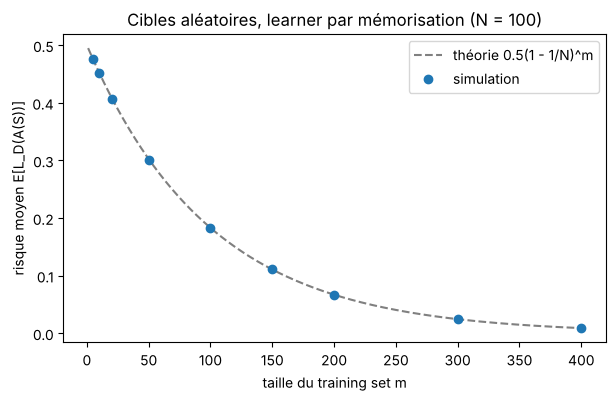

In [ ]:
N = 100
m_nfl = [5, 10, 20, 50, 100, 150, 200, 300, 400]
risque_alea = []
for m in m_nfl:
    _, r = experience_nfl(N, m, 2000)
    risque_alea.append(r)
theorie = [0.5 * (1 - 1/N)**m for m in m_nfl]

print("   m   risque simulé   0.5(1 - 1/N)^m")
for m, r, t in zip(m_nfl, risque_alea, theorie):
    print(f"{m:4d}   {r:13.4f}   {t:14.4f}")

plt.figure(figsize=(7, 4))
m_fin = np.arange(1, 401)
plt.plot(m_fin, 0.5 * (1 - 1/N)**m_fin, "--", color="gray", label="théorie 0.5(1 - 1/N)^m")
plt.plot(m_nfl, risque_alea, "o", label="simulation")
plt.xlabel("taille du training set m")
plt.ylabel("risque moyen E[L_D(A(S))]")
plt.title("Cibles aléatoires, learner par mémorisation (N = 100)")
plt.legend()
plt.show()

**Commentaire.**

- La simulation et la formule sont presque identiques (0.4753 contre 0.4755 pour $m = 5$, 0.1834 contre 0.1830 pour $m = 100$) : les points de la simulation tombent sur la courbe théorique.
- Le learner fait **exactement 50 % d'erreurs sur les points qu'il n'a pas vus**. Son risque ne diminue que parce que le nombre de points vus augmente, pas parce qu'il apprend quelque chose sur les autres.
- Tant que $m < N/2 = 50$ (la condition du théorème NFL), le risque reste au-dessus de 0.30. Il ne devient petit que lorsque $m$ dépasse largement $N$, c'est-à-dire quand le learner a presque tout vu : ce n'est plus de la généralisation, c'est de la mémorisation.

### 8. Changer la prédiction sur les points jamais vus

Je compare trois règles pour les points non vus : toujours prédire 0, toujours prédire 1, et prédire un label au hasard.

In [ ]:
print("   m   prédire 0   prédire 1   au hasard")
regles = {"0": [], "1": [], "hasard": []}
for m in [10, 50, 100, 200]:
    ligne = []
    for regle in regles:
        _, r = experience_nfl(N, m, 2000, regle)
        regles[regle].append(r)
        ligne.append(r)
    print(f"{m:4d}   {ligne[0]:9.4f}   {ligne[1]:9.4f}   {ligne[2]:9.4f}")

   m   prédire 0   prédire 1   au hasard


  10      0.4527      0.4520      0.4521


  50      0.3031      0.3030      0.3025


 100      0.1827      0.1841      0.1830


 200      0.0667      0.0666      0.0677


**Commentaire.**

- Les trois règles donnent le même risque à moins de 0.002 près, pour toutes les tailles (par exemple 0.453, 0.452 et 0.452 pour $m = 10$). Les petites différences viennent seulement du hasard de la simulation, et aucune règle n'est meilleure de façon régulière.
- C'est exactement le No-Free-Lunch : quand on fait la moyenne sur **toutes** les fonctions cibles possibles, le label d'un point non vu vaut 0 dans la moitié des tâches et 1 dans l'autre moitié. Quelle que soit la prédiction choisie, elle est juste une fois sur deux.
- Une règle ne pourrait faire mieux que si elle **supposait** quelque chose sur la cible (par exemple « il y a plus de 0 que de 1 »). Mais ce serait de la connaissance a priori, et la même règle perdrait sur les tâches où cette supposition est fausse.

Le training set seul ne permet donc pas de deviner les labels des points non vus.

## Partie III – Ajouter de la connaissance a priori

Même domaine $\mathcal{X} = \{1, \dots, N\}$ avec $N = 100$, mais la cible n'est plus quelconque : c'est un seuil $f_\theta(x) = \mathbb{1}[x > \theta]$, avec $\theta$ tiré au hasard dans $\{1, \dots, N-1\}$ à chaque répétition.

Le learner utilise ERM sur la classe des seuils $\mathcal{H} = \{h_t(x) = \mathbb{1}[x > t] : t \in \{1, \dots, N-1\}\}$. Il teste tous les seuils et garde le milieu de ceux qui ont la plus petite erreur empirique. L'erreur vraie se calcule exactement sur tout le domaine : $h_t$ se trompe sur les points entre $t$ et $\theta$, donc $L_D(h_t) = |t - \theta|/N$.

### 9. Apprendre avec un inductive bias adapté

In [ ]:
def erm_seuil(x, y, N):
    # teste tous les seuils t = 1..N-1 et garde le milieu des meilleurs
    seuils = np.arange(1, N)
    pred = (x[None, :] > seuils[:, None]).astype(int)
    erreurs = np.mean(pred != y, axis=1)
    meilleurs = seuils[erreurs == erreurs.min()]
    return meilleurs[len(meilleurs) // 2]

def experience_seuil(N, m, n_rep):
    risque = np.zeros(n_rep)
    for r in range(n_rep):
        theta = rng.integers(1, N)           # seuil cible tiré au hasard dans 1..N-1
        x = rng.integers(1, N + 1, m)        # training set dans X = {1, ..., N}
        y = (x > theta).astype(int)
        t = erm_seuil(x, y, N)
        risque[r] = abs(t - theta) / N       # proportion des points de X mal classés
    return risque.mean()

risque_seuil = [experience_seuil(N, m, 2000) for m in m_nfl]

print("   m   cibles seuils (ERM)   cibles aléatoires")
for m, a, b in zip(m_nfl, risque_seuil, risque_alea):
    print(f"{m:4d}   {a:19.4f}   {b:17.4f}")

   m   cibles seuils (ERM)   cibles aléatoires
   5                0.0715              0.4753
  10                0.0407              0.4518
  20                0.0227              0.4073
  50                0.0087              0.3007
 100                0.0040              0.1834
 150                0.0020              0.1114
 200                0.0012              0.0666
 300                0.0005              0.0244
 400                0.0002              0.0091


**Commentaire.**

- Avec des cibles seuils, le risque est très faible même avec peu de données : 0.07 pour $m = 5$, 0.02 pour $m = 20$, moins de 0.01 à partir de $m = 50$.
- Avec des cibles aléatoires et le même nombre d'exemples, il vaut 0.48, 0.41 et 0.30. Pour $m = 20$, l'erreur est environ 18 fois plus petite avec les seuils.
- Le risque est à peu près divisé par 2 chaque fois que $m$ double (0.041, 0.023, … ), comme dans le cas réalisable du HW1.
- Ce risque est calculé sur **tout** le domaine, y compris les points jamais vus. Contrairement à la partie II, le learner a donc raison sur la plupart des points qu'il n'a jamais observés.

### 10. Cibles aléatoires contre cibles structurées

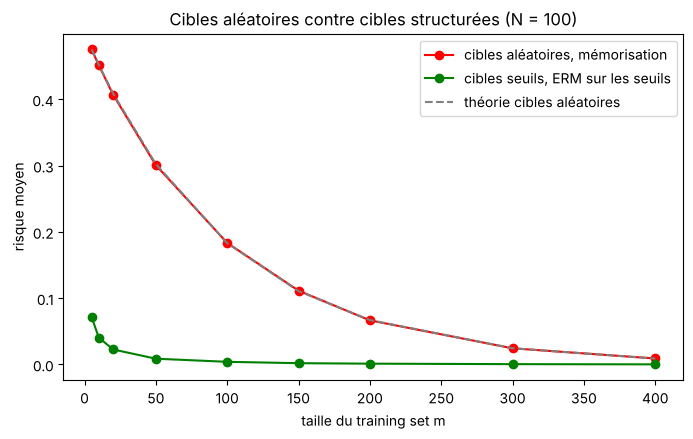

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(m_nfl, risque_alea, "o-", color="red", label="cibles aléatoires, mémorisation")
plt.plot(m_nfl, risque_seuil, "o-", color="green", label="cibles seuils, ERM sur les seuils")
plt.plot(m_nfl, [0.5 * (1 - 1/N)**m for m in m_nfl], "--", color="gray", label="théorie cibles aléatoires")
plt.xlabel("taille du training set m")
plt.ylabel("risque moyen")
plt.title("Cibles aléatoires contre cibles structurées (N = 100)")
plt.legend()
plt.show()

**Commentaire.**

Avec des cibles aléatoires, connaître le label d'un point ne dit **rien** sur ses voisins, car tous les labels sont indépendants. Le learner ne peut que mémoriser.

Avec des cibles seuils, chaque exemple donne de l'information sur beaucoup d'autres points : si $x$ a le label 0, alors tous les points plus petits que $x$ ont aussi le label 0, et si $x$ a le label 1, tous les points plus grands ont le label 1. Il ne reste d'incertitude que dans l'intervalle entre le plus grand point de label 0 et le plus petit point de label 1, et cet intervalle devient très petit dès qu'on a quelques dizaines d'exemples.

Tout repose sur l'hypothèse que **la cible appartient à la famille des seuils**. C'est ce qui permet de déduire les labels des points non vus. C'est un inductive bias : on a restreint à l'avance les cibles possibles (de $2^{100}$ fonctions à 99 seuils). Si la vraie cible n'était pas un seuil, ce même learner se tromperait, ce qui est cohérent avec le NFL : le gain sur les seuils est obtenu en renonçant à bien apprendre les autres cibles.

## 11. Conclusion

- **$L_S(h)$ se concentre autour de $L_D(h)$ quand $m$ augmente**, parce que c'est une moyenne de $m$ erreurs indépendantes : sa moyenne reste $L_D(h)$ et son écart-type diminue comme $1/\sqrt{m}$ (de 0.145 à 0.010 entre $m = 10$ et $m = 2000$).
- **La uniform convergence demande de contrôler toutes les hypothèses en même temps**, car ERM choisit son hypothèse à partir de $S$. Il suffit qu'une seule erreur empirique soit trop optimiste pour que ERM risque de la choisir. Pour $m = 500$, l'échec arrive dans 1 % des cas pour une hypothèse, mais dans 12 % des cas pour une classe de 10.
- **Plus $|\mathcal{H}|$ est grand, plus ce contrôle simultané est difficile**, et plus il faut de données. Mais l'effet est logarithmique : une classe 100 fois plus grande ne demande qu'environ 2.7 fois plus d'exemples (de 500 à 1350).
- **Les bornes théoriques sont conservatives** : Hoeffding est écrit pour le pire cas, la union bound additionne des probabilités qui se recouvrent, et la garantie doit tenir pour toutes les distributions. En pratique, il a suffi de 1.5 à 2 fois moins d'exemples que la borne.
- **Avec des cibles complètement aléatoires, les labels des points non vus sont imprévisibles**, car ils sont indépendants de ceux du training set. Le learner fait 50 % d'erreurs sur ces points, quelle que soit sa règle de prédiction.
- **Le No-Free-Lunch** se voit directement : le risque suit exactement $\frac{1}{2}(1 - 1/N)^m$ et ne diminue que parce que de plus en plus de points sont vus. Le training set seul ne permet pas de deviner les labels manquants.
- **Restreindre la cible et la classe d'hypothèses aux seuils introduit de la connaissance a priori** : on suppose à l'avance la forme de la cible.
- **C'est cet inductive bias qui permet de généraliser** : grâce à la structure de seuil, chaque exemple renseigne sur tout un intervalle de points non vus. Avec $m = 20$, l'erreur passe de 0.41 (cibles aléatoires) à 0.02 (cibles seuils).

En résumé : avec assez de données, une classe finie et pas trop grande, l'erreur empirique devient un bon reflet de l'erreur vraie. Mais les données seules ne suffisent pas à généraliser : il faut aussi une hypothèse sur la forme de la cible.